Adding Parameter Optimization
==

DIN supplement, cycling

Top-down control by zoop, virus

This version builds on bloom_lagrangian_zoop_etal_tuning, and continues the work on 
parameter optimization.

In [181]:
import matplotlib.pyplot as plt
%matplotlib widget

In [182]:
import sys
s="/richmondvol1/rusty/stompy"
if s not in sys.path: sys.path.append(s) 
    
from importlib import reload
import time
import datetime
import os

from IPython.display import Video

import matplotlib.colorbar as cbar
import pandas as pd
import numpy as np
import xarray as xr

from scipy.integrate import solve_ivp
from matplotlib import colors, cm, ticker
import seaborn as sns

from stompy import utils, memoize, xr_utils, xr_transect
import stompy.model.delft.dflow_model as dfm
import stompy.model.delft.waq_scenario as dwaq
from stompy.plot import plot_utils, plot_wkb, mkanim
import stompy.plot.cmap as scmap
from stompy.spatial import field, proj_utils
from stompy.grid import unstructured_grid

In [183]:
# These are online-coupled dfm-dwaq runs.
import bloom_common
reload(bloom_common)
from bloom_common import load_model, ratio, chl_from_RS

In [184]:
turbo_low = scmap.cmap_transform(cm.turbo,lambda i: i**0.75)

Load Supporting Data
==

In [185]:
mooring_ll=pd.read_csv("../Kd_2022/L2/latlon.csv", sep="\t").set_index('station')
mooring_ll

,latitude,longitude
station,,
Dumbarton Bridge,37.50417,-122.119
Alviso Slough,37.44000,-121.998
San Mateo Bridge,37.58444,-122.249
Guadalupe Slough,37.43468,-122.026
Newark Slough,37.51338,-122.082
Mowry Slough,37.48536,-122.033
Pond A8 outlet,37.42348,-121.980
Coyote Creek,37.46384,-122.024
Shoal,37.63079,-122.243


In [372]:
# Mooring data:
def load_mooring(site='SHL',location_name='Shoal'):
    # site: SHL, SLM, HAY, DMB, SM
    # location_name: match station column in latlon.csv.
    #  "Shoal", "SanLeandroMarina", "Hayward", "Dumbarton Bridge", "San Mateo Bridge"
    mooring_csv=f"../Kd_2022/L2/{site}_all_data_L2.csv"
    df_mooring = pd.read_csv(mooring_csv, low_memory=False)
    del df_mooring['Unnamed: 0']
    df_mooring['time'] = pd.to_datetime(df_mooring['dt'])
    df_mooring['time'] = df_mooring.time.values # should get back to UTC

    if site=='DMB':
        sel=((df_mooring.time.values>np.datetime64("2022-08-24 11:31")) 
             & (df_mooring.time.values<np.datetime64("2022-09-07 20:16"))) 
        # Based on periodicity and plotting SUNA vs EXO, this gives solid 
        # agreement between SUNA temperature and EXO temperature at DMB
        # over 2022-08-01 -- 2022-09-15
        print("Selectively applying DMB EXO time correction, +7h for ~2 weeks")
        df_mooring['time'].values[sel] += np.timedelta64(7,'h')
    elif site=='SHL':
        # There was a discrepancy between SHL exo and SUNA.
        # Based on comparison to DFM output, which was previously ground-truthed against
        # DMB data, it appears that the EXO data is coming in as PST even after the adjustment
        # that pandas does when reading the -0800 suffix.
        print("Applying SHL EXO time correction, +8 h")
        df_mooring['time'].values[:] += np.timedelta64(8,'h')
    elif site=='SLM':
        sel=((df_mooring.time.values>np.datetime64("2022-08-10 13:01")) 
             & (df_mooring.time.values<np.datetime64("2022-09-07 18:14"))) 

        # Based on comparison to DMB and SHL after chasing down corrections to those.
        print("Selectively applying SLM EXO time correction, +7h for ~3 weeks")
        df_mooring['time'].values[sel] += np.timedelta64(7,'h')
    elif site=='HAY':
        # Based on comparison to SHL, after chasing down the offsets to SHL
        print("Applying HAY EXO time correction, +8 h")
        df_mooring['time'].values[:] += np.timedelta64(8,'h')

    # Trim to columns we need
    df_mooring = df_mooring[ ['time','Chla_microgL','S_PSU','T_degC','Turb_FNU'] ]
    
    # Merge SUNA data before clipping, resampling, etc.
    if site=='DMB':
        suna_df=pd.read_csv("data_suna/DMB_ALL_2026_07_02.csv")
        suna_df['time'] = pd.to_datetime(suna_df['ts_pst']) + np.timedelta64(8,'h')
    elif site=='SHL':
        suna_df = pd.read_csv("data_suna/SHL_ALL_2026_08_14.csv")
        suna_df['time'] = pd.to_datetime(suna_df['ts_pst']) + np.timedelta64(9,'h') # Strange, but I think correct.
    else:
        suna_df = None
    if suna_df is not None:
        # merge into df_mooring by matching time, copy over 
        # 'T_degC', 'S_PSU', 'NO3_uMol', 'time'
        # all with _suna suffix
        df_mooring=pd.merge(df_mooring, 
                            # DEV
                            #suna_df[ ['time','T_degC','S_PSU','NO3_uMol'] ],
                            # PRODUCTION
                            suna_df[ ['time','NO3_uMol'] ],
                            on='time', how='left', suffixes=('','_suna'))
    
    # dt has the time zone in it, and .values should get a UTC timestamp, ready for comparison to model output
    sel=(df_mooring.time.values>np.datetime64("2022-08-01")) & (df_mooring.time.values<np.datetime64("2022-09-10"))
    df_mooring = df_mooring.iloc[sel,:]

    df_mooring = df_mooring.set_index('time').resample('1H').mean().reset_index()

    # For now just a single mooring, but could be multiple moorings
    df_mooring['site']=site

    lonlat = np.r_[mooring_ll.loc[location_name,'longitude'], mooring_ll.loc[location_name,'latitude']]
    xy = proj_utils.mapper('WGS84','EPSG:26910')(lonlat)
    df_mooring['x']=xy[0]
    df_mooring['y']=xy[1]
    return df_mooring

df_SHL = load_mooring('SHL',"Shoal")
df_SLM = load_mooring('SLM',"SanLeandroMarina")
df_DMB = load_mooring('DMB',"Dumbarton Bridge")
df_HAY = load_mooring('HAY',"Hayward")

Applying SHL EXO time correction, +8 h
Selectively applying SLM EXO time correction, +7h for ~3 weeks
Selectively applying DMB EXO time correction, +7h for ~2 weeks
Applying HAY EXO time correction, +8 h


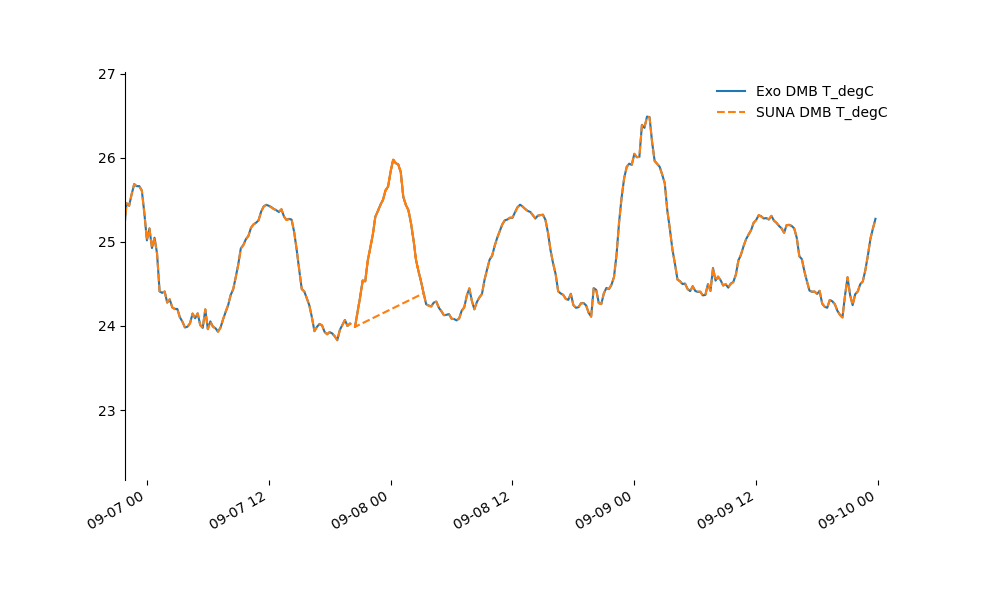

In [358]:
# Minor bit of dev for bringing SUNA data in
# Based on the column names in the CSVs we should need a +8h shift to get to UTC to
# match load_mooring(). In load_mooring() the times are written as PST *with a timezone*
# which is parsed as such, and the internal time is automatically shifted to the correct
# UTC.
# Assume that DMB is mostly correct. There is a period where DMB needed extra shifting, which
# is now baked into load_mooring() and we have solid agreement between DMB's EXO and SUNA
# with that shift of the EXO in place, shifting the DMB SUNA data based on the
# advertised PST leads to good agreement in salinity and temperature time series.

# Either
# (A) SHL SUNA is almost already in UTC, just needs 1h more shift, or
# (B) SHL Exo is in PDT

# Comparing SHL and DMB salinity signal is not useful. Maybe temperature?


# def load_and_merge_suna(df, suna_fn)
# These files have a ts_pst column, and entries that do *not* mention time zone
#dmb_suna_df=pd.read_csv("data_suna/DMB_ALL_2026_07_02.csv")
#shl_suna_df = pd.read_csv("data_suna/SHL_ALL_2026_08_14.csv")

#for suna_df in [dmb_suna_df, shl_suna_df]:
#    if suna_df is dmb_suna_df:
#        t_offset = np.timedelta64(8,'h')
#    else:    
#        t_offset = np.timedelta64(9,'h') # Strange, but I think correct.
#    suna_df['time'] = pd.to_datetime(suna_df['ts_pst']) + t_offset
#    del suna_df['ts_pst']


# Visual inspection of fields:
# NO3_mgNL is presumably what we want. The other have some large negative swings at times,
# and the Raw label is scary. Good data coverage at DMB for the bloom period.
# SHL has a few short periods of missing data. Not bad at all. It does get clipped at zero
# for some of the time.


if 0:
    # This needs T_degC and S_PSU from SUNA enabled above
    # Checking time zones:
    # 
    #fld='S_PSU'
    fld='T_degC'
    fig,ax=plt.subplots(figsize=(10,6))
    
    #ax.plot(shl_suna_df.time, shl_suna_df[fld],label=f"SUNA SHL {fld}")
    #ax.plot(dmb_suna_df.time, dmb_suna_df[fld],label=f"SUNA DMB {fld}")
    #ax.plot(df_SHL.time, df_SHL[fld], label=f'Exo SHL {fld}', ls="-")
    #ax.plot(df_SHL.time, df_SHL[fld+'_suna'], label=f'SUNA SHL {fld}', ls="--")
    ax.plot(df_DMB.time, df_DMB[fld], label=f'Exo DMB {fld}', ls="-")
    ax.plot(df_DMB.time, df_DMB[fld+'_suna'], label=f'SUNA DMB {fld}', ls="--")

    # Might as well check the other sites, given how unreliable these were
    #ax.plot(df_SLM.time, df_SLM[fld], label=f'Exo SLM {fld}')
    #ax.plot(df_HAY.time, df_HAY[fld], label=f'Exo HAY {fld}',lw=2.5)
    
    ax.axis(xmin=np.datetime64('2022-08-01'),xmax=np.datetime64('2022-09-10'))
    #ax.axis(ymin=-0.1,ymax=1.1)
    
    fig.autofmt_xdate()
    ax.axhline(0,color='k',lw=0.75, alpha=0.3)
    ax.spines['top'].set_visible(0)
    ax.spines['bottom'].set_visible(0)
    ax.spines['right'].set_visible(0)
    ax.legend(frameon=0)

    # SUNA Salinity and regular mooring salinity are 180 out of phase.
    # low tide we get fresh water, but that's also sampling th
    # Best guess is that ts_pst in the suna data is already UTC

    ax.axis((19241.910153963487, 19245.090206966357, 22.1681266781469, 27.021366269576824))

    # DMB Exo appears to have been serviced 2022-08-24. Before that moment
    # DMB Exo time seems correct, and afterwards it appears to have lost its
    # shift, until 2022-09-08 00:00.

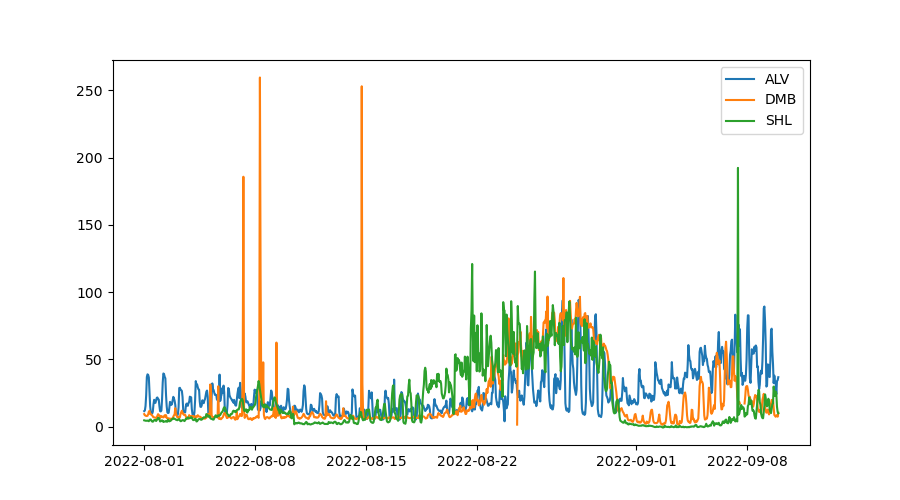

In [164]:
if 1: # Check San Mateo Bridge, Alviso Slough for additional data
    # maybe?? SM is missing a chunk and has very similar signal to SHL
    # ALV shows a higher baseline before/after, and delayed arrival of
    # the HAB. The higher baseline, presumably due to local production
    # that's not heterosigma, will confuse fitting...
    df_SM = load_mooring('SM','San Mateo Bridge')
    df_ALV = load_mooring('ALV','Alviso Slough')
    #df_NW = load_mooring('NW','Newark Slough') # extraneous(?) signal before 8/13 or so
    #df_MOW = load_mooring('MOW','Mowry Slough') # no data
    
    fig,ax = plt.subplots(figsize=(9,5))
    #ax.plot(df_SM.time, df_SM.Chla_microgL,label='SM')
    ax.plot(df_ALV.time, df_ALV.Chla_microgL,label='ALV')
    ax.plot(df_DMB.time, df_DMB.Chla_microgL,label='DMB')
    ax.plot(df_SHL.time, df_SHL.Chla_microgL, label='SHL')
    #ax.plot(df_NW.time, df_NW.Chla_microgL, label='NW')
    #ax.plot(df_MOW.time, df_MOW.Chla_microgL, label='MOW')
    ax.legend()

In [12]:
if 0:
    fig,ax = plt.subplots()

    for df in [df_SHL,df_SLM,df_DMB]:
        ax.plot(df.time, df.Chla_microgL, label=df.site.values[0])
    ax.set_ylabel(f"{df_mooring.site.values[0]} chl-a ug/l")
    ax.legend()
    fig.autofmt_xdate()

In [13]:
# Confirm mooring location
if 0:
    fig,ax=plt.subplots()
    grid=tracer_groups[0].grid
    grid.plot_edges(color='0.6',alpha=0.5,lw=0.5)
    for df in [df_SHL,df_SLM,df_DMB]:
        ax.plot(df.iloc[0].x, df.iloc[0].y,'ro')
        ax.text(df.iloc[0].x, df.iloc[0].y,df.site.values[0])
    ax.axis('off')

In [178]:
import tracer_group
reload(tracer_group)
from tracer_group import TracerGroup, tracer_groups

# Alameda release is basically zero until after the first pulse of bloom
# South Bay release shows up too early for DMB, SLM

ic_name='alameda'
#ic_name='southbay'

# v17 has temperature and extends through 9/5
tg = [t for t in tracer_groups if t.tag=='v17' and t.swim==6.912 and t.initial==ic_name][0]

In [15]:
grid_poly = tracer_groups[0].grid.boundary_polygon()

INFO:utils:82640/86633
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:join_features:0 open strings, 16 simple polygons
INFO:join_features:Building index
INFO:UnstructuredGrid:Warning, boundary_polygon() failed using edges!  Trying polygon uni

Checking Time Offsets
==

In [293]:
# Is there a T or S signal to compare with?
# S is not great -- model shows a local maximum around SHL. DMB has more obvious typical gradient.
# S time series at SHL don't give any hint about time shifts.
# T at Dumbarton, while not a glowing validation, suggests that times are aligned between the model
# and the Exo, and we know from above that the EXO and the SUNA are now aligned.
# S time series at Dumbarton further confirms alignment.

In [359]:
if 0:
    # These findings are already incorporated in the code above
    # Temp comparison at moorings
    for site in ['SHL','DMB','SLM','HAY']:
        if site=='SHL':
            df_exo = df_SHL
        elif site=='DMB':
            df_exo = df_DMB
        elif site=='SLM':
            df_exo = df_SLM
        elif site=='HAY':
            df_exo = df_HAY
        else: assert False
            
        site_xy = df_exo[ ['x','y'] ].values[0]
        site_cell = tg.grid.select_cells_nearest(site_xy)
        
        site_salt_dfm = tg.ds['sa1'].isel(laydim=-1, nFlowElem=site_cell) 
        site_temp_dfm = tg.ds['tem1'].isel(laydim=-1, nFlowElem=site_cell) 
        
        salt_dfm_snap = tg.ds['sa1'].isel(laydim=-1).sel(time=np.datetime64('2022-08-10'), method='nearest')
        temp_dfm_snap = tg.ds['tem1'].isel(laydim=-1).sel(time=np.datetime64('2022-08-10'), method='nearest')
        
        fig,(ax_map,ax_ts) = plt.subplots(1,2,figsize=(10,6))
        ax_map.set_adjustable('datalim')
        tg.grid.plot_cells(ax=ax_map,mask=[site_cell],labeler=lambda i,r: site, visible=0)
        tg.grid.plot_cells(ax=ax_map,
                           #values=salt_dfm_snap.values,clim=[29,33],
                           values=temp_dfm_snap.values,clim=[10,26],
                           lw=0.5,ec='face',cmap='turbo')
        
        ax_map.axis((550755.7126033807, 579514.8856224886, 4135909.1748221535, 4183055.6642682403))
        
        #ax_ts.plot(site_salt_dfm.time, site_salt_dfm, label='DFM modeled S')
        #ax_ts.plot(df_exo.time, df_exo['S_PSU'], label=f'Exo {site} S')
        ax_ts.plot(site_temp_dfm.time, site_temp_dfm, label='DFM modeled T')
        ax_ts.plot(df_exo.time, df_exo['T_degC'], label=f'Exo {site} T')
        ax_ts.legend(loc='upper left')

Model Code
==

In [363]:
from stompy import memoize
class LagrangianModel:    
    # Any parameters that are available for tuning go here with defaults
    base_params=dict(
        thresh=1e-2,
        c0=3,
        kprod=1.0,
        N0=35, # initial DIN, uM
        Nsat=0.5, # half-sat DIN, uM
        Z0=0.1, # initial zoop. units?
        kmort=0.05,
        Isat=10.0,
        background=4.0, # baseline chl, added to result after the fact.
        alpha=0.15, # stoichiometry
        mu_Z=0.1, # growth rate for Zoop
    )


    # expects fields in dataframe:
    # x,y -  location of the sample
    # time 
    # optionally observed values, e.g. Chla_microgL 
    df_inputs=None # determines the samples that will be simulated. 
    
    group=None # tracer group
    layer=15 # model layer requires some preprocessing and it's discrete, not available for tuning
    light_lim='mean_lim' # approach to calculating light limitation
    # 'mean_lim', 'lim_mean'. May eventually have 'mean_lim_selfshade'
    # What to report when there's not enough tracer to do anything:
    P_nodata=np.nan
    N_nodata=np.nan 

    min_ageconc = 1e-5 # threshold passed to bloom_common.ratio()
    drop_by_ageconc = False # False: keep inputs even if they will be nan. True: drop them from the inputs. 
    
    def __init__(self,params={},**kw):
        # Makes a copy for this instance. So you can have the "global" defaults defined above,
        # set some "instance" defaults, and still tune some parameters with different values within
        # and instance. 
        self.base_params = self.base_params | params # params will take precedence
        utils.set_keywords(self,kw)
        assert self.df_inputs is not None,"Must specify df_inputs"
        self.prepare_inputs()
        self.parameter_sets=[]
        self.evaluate_parameter_set()

    @memoize.imemoize()
    def xy_to_cell(self,xy):
        return self.group.grid.select_cells_nearest(xy)
            
    def prepare_inputs(self):
        """
        Copy and augment df_inputs with tracer data.
        """
        xy = self.df_inputs[ ['x','y'] ].values
        cells = np.array([self.xy_to_cell(p) for p in xy])
        
        # Some may be -1
        tidx = utils.nearest(self.group.ds.time.values, self.df_inputs.time.values, max_dx = np.timedelta64(1,'h'))
        valid = tidx>=0

        # Filter to samples that are covered by the tracer data
        self.df_inputs = self.df_inputs.loc[ valid, :].copy()
        self.df_inputs['cell'] = cells[valid]
        self.df_inputs['tidx'] = tidx[valid]

        df_data = self.group.extract_timeseries(self.df_inputs.tidx.values, self.df_inputs.cell.values, layer=self.layer)
        for col in df_data.columns:
            self.df_inputs[col] = df_data[col].values
        self.df_inputs['conc'] = self.df_inputs['conc'].clip(0.0)        
    
        if self.drop_by_ageconc:
            ageconc_valid = (self.df_inputs['conc']*self.df_inputs['age_d']).values >= self.min_ageconc
            self.df_inputs = self.df_inputs.loc[ageconc_valid, :].copy() 
        
    def evaluate_parameter_set(self,**kw):
        """
        Runs the forward model on all samples in self.df_inputs, 
        using any specified parameters, falling back to base_params.
        Returns dataframe with the results.
        kw can include any fields from base_params.
        """
        t0=time.time()
        # params that are set across an evaluation of all the data points
        params=self.base_params | kw
        self.parameter_sets.append(params) # or just log kw
            
        # ODE integration
        # State vector is [N, P, Z, I, V]
    
        recs=[]
        
        for i,row in utils.progress(enumerate(self.df_inputs.itertuples()),msg="Evaluate samples: %s"):
            constant_params=dict(params) # make a copy so code in this loop can use df_inputs to modify parameters. 
            IC=np.r_[params['N0'], params['c0']*row.conc, params['Z0'], params['I0'], params['V0']]
            age_d=row.age_d
            # self-shading would probably mean kLight is at least partially calculated inside the
            # integration
            constant_params['kLight']=bloom_common.calc_kLight(Isat=constant_params['Isat'],
                                                               kRadA=row.kRadA,IsatA=row.IsatA,
                                                               kRadB=row.kRadB,IsatB=row.IsatB,
                                                               conc=row.conc,age_d=row.age_d)
            if np.isnan(constant_params['kLight']):
                result = np.nan*IC
            elif age_d>0:
                bunch = solve_ivp(self.npziv_diff, y0=IC, t_span=[0,row.age_d], args=(constant_params,))
                result=bunch.y[:,-1]
            else:
                result = IC
            recs.append(dict(N=result[0],
                             P=result[1]+constant_params['background'],
                             Z=result[2],
                             I=result[3],
                             V=result[4],
                             time=row.time)
                        | constant_params)
        self.df_result=pd.DataFrame(recs)
    
        elapsed=time.time() - t0
        param_str=",".join( [f'{k}={params[k]:.3f}' for k in params] )
        #print(f"solveNPZIV({param_str}) in {elapsed:.3f}s")

    # Can override in subclass
    def npziv_diff(self, t, state, params):
        N,P,Z,I,V=np.clip(state,0,None)

        kDIN    =  N/(N+params['Nsat'])
        dgrossP =  params['kprod']*params['kLight']*kDIN*P
        dnetP   = -params['kmort']*P + dgrossP
        dN      = -params['alpha']*dgrossP
        dZ      =  params['mu_Z']*Z
        # default derivative ignores infected and virus state
        return np.r_[dN,dnetP,dZ,0,0]

    @property
    def df_merged(self):
        return pd.concat([self.df_result, self.df_inputs.reset_index()], axis=1)
        
def fig_time_series(model, df_result=None, mask=None):
    if df_result is None:
        df_result = model.df_result
    fig,axs = plt.subplots(4,1,sharex=True,figsize=(7,6.5))

    df_inputs=model.df_inputs

    if mask is not None:
        df_inputs = df_inputs.loc[mask,:]
        df_result = df_result.loc[mask,:]
        
    ax=axs[0]
    site = df_inputs.site.values[0]
    #ax.plot(model.df_observations.time, model.df_mooring.Chla_microgL, label=f'{site} mooring')
    ax.plot(df_inputs.time, df_inputs.Chla_microgL, label=f'{site} mooring')
    ax.plot(df_result.time, df_result.P, label='Lagrangian')
    ax.set_ylabel('Chl-a (ug/l)')
    ax.legend(loc='upper left')
    ax.axis(ymin=0)
    
    ax=axs[1]
    ax.plot(df_result.time, df_result.N)
    ax.set_ylabel('N ($\\mu$M)',color=ax.lines[0].get_color())
    ax.axis(ymin=-0.5)
    ax=ax.twinx()
    ax.plot(df_result.time, df_result.Z,color='tab:orange')
    ax.set_ylabel('Z (-)',color='tab:orange')
    
    ax=axs[2]
    ax.plot(df_inputs.time, df_inputs.conc)
    ax.set_ylabel('Tracer conc')
    ax.axis(ymin=-0.025)
    
    ax=axs[3]
    ax.plot(df_result.time, df_result.kLight)
    ax.set_ylabel('kLight (-)')
    ax.axis(ymin=0)
    
    fig.autofmt_xdate()
    fig.subplots_adjust(top=0.98,bottom=0.1,left=0.1,right=0.87,hspace=0.07)
    return fig

def fig_time_series_with_virus(model, df_result=None, mask=None):
    if df_result is None:
        df_result = model.df_result
    fig,axs = plt.subplots(4,1,sharex=True,figsize=(7,6.5))

    df_inputs = model.df_inputs

    if mask is not None:
        df_inputs = df_inputs.loc[mask,:]
        df_result = df_result.loc[mask,:]

    ax=axs[0]
    site = df_inputs.site.values[0]
    # Note - df_inputs is already decimated, but the corresponding df_mooring is not. Could include as optional var
    #ax.plot(model.df_mooring.time, model.df_mooring.Chla_microgL,label=f'{site} mooring')
    ax.plot(df_inputs.time, df_inputs.Chla_microgL, label=f'{site} mooring (sampled)')
    ax.plot(df_result.time, df_result.P, label='Lagrangian')
    ax.set_ylabel('Chl-a (ug/l)')
    ax.legend(loc='upper left')
    if 1: # drop outliers from limits calc
        ymax = max(df_inputs.Chla_microgL.quantile(0.995),
                   df_result.P.max())
        ax.axis(ymin=0,ymax=ymax)
    
    ax=axs[1]
    ax.plot(df_result.time, df_result.N)
    ax.set_ylabel('N ($\\mu$M)',color=ax.lines[0].get_color())
    ax.axis(ymin=-0.5)
    if np.any(df_result.Z>0.0):
        ax=ax.twinx()
        ax.plot(df_result.time, df_result.Z,color='tab:orange')
        ax.set_ylabel('Z (-)',color=ax.lines[0].get_color())
        plt.setp(ax.get_yticklabels(), color=ax.lines[0].get_color())
        ax.axis(ymin=-0.01)

    has_virus=np.any(df_result.I.values>0)

    if has_virus:
        ax=axs[2]
        ax.plot(df_result.time, df_result.I, color='tab:red')
        ax.set_ylabel('Infected (ug chl/l)',color=ax.lines[0].get_color())
        plt.setp(ax.get_yticklabels(), color=ax.lines[0].get_color())
        ax.axis(ymin=0)
        ax=ax.twinx()
        ax.plot(df_result.time, df_result.V, color='tab:orange')
        ax.set_ylabel('Virus ($\\sim$VLP mL$^{-1}$)',color=ax.lines[0].get_color())
        plt.setp(ax.get_yticklabels(), color=ax.lines[0].get_color())
        ax.axis(ymin=0)
    else:
        axs[2].set_visible(0)

    ax=axs[3]
    ax.plot(df_inputs.time, df_inputs.conc)
    ax.set_ylabel('Tracer conc')
    ax.axis(ymin=-0.025)
    
    fig.autofmt_xdate()
    fig.subplots_adjust(top=0.98,bottom=0.1,left=0.13,right=0.87,hspace=0.07)
    return fig


# handle types of input by composition, with prepare* and plot* methods
# single mooring, multiple mooring, single RS scene, multiple RS scene.
def prepare_mooring_input(df_mooring,stride=1):
    return df_mooring.iloc[::stride].copy()

def prepare_moorings_input(dfs,stride=1):
    dfs=[prepare_mooring_input(df,stride) for df in dfs]
    return pd.concat(dfs)
    

In [364]:
class NPZIVModel(LagrangianModel):
    base_params=dict(
        N0=35, # initial DIN, uM
        # P0=c0*tracer conc
        Z0=0.1, # initial zoop. units?
        I0=0.0,
        V0=0.0,
        c0=3, # scale tracer output to get initial concentration
        kprod=1.0, # maximum instantaneous phyto growth rate [1/d]
        Nsat=0.5, # half-sat DIN, uM
        Isat=10.0, # half-sat for light, in some version(?) of W/m2
        kmortP=0.05, # phyto mortality rate [1/d]
        kmortZ=0.2, # zooplankton mortality rate [1/d]
        background=2.0, # baseline chl, added to result after the fact.
        alpha=0.15, # stoichiometry
        Z_efficiency=0.3, # growth efficiency for zoop,
        Z_max_ration=1.5, # maximum ration for zooplankton [1/d]
        mortP_to_N_efficiency = 0.5,
        N_supplement = 1.0, # uM/day
        thresh=1e-2,
        Ivlev=1.0, # Ivlev constant, 1.0  [ 1/(uM N) ]
        k_infect=0.0, # or 6.75e-8 [mL VLP^-1 day^-1] (adjust based on assumed units for P and V)default=5e-9
        lambda_lysis=1.5, # (float): Lysis rate of infected phytoplankton [day^-1]
        B=500, # viruses per 'host unit'; default=500
        k_virus=0.25, # Viral decay/inactivation rate [day^-1]
    )

    def npziv_diff(self, t, state, params):
        N,P,Z,I,V=np.clip(state,0,None)

        dN=dP=dZ=dI=dV=0.0
        
        has_virus = (V+I>0)
        has_zoop  = (Z>0)

        # N-P
        lim_DIN=N/(N+params['Nsat'])

        # No self-shading
        dgrossP = params['kprod']*params['kLight']*lim_DIN*P
        dmortP = params['kmortP']*P # positive value, but represents loss of P
        dnetP = dgrossP - dmortP

        dN = (
            - params['alpha']*dgrossP # uptake
            + params['alpha']*params['mortP_to_N_efficiency']*dmortP # recycling
            + params['N_supplement'] # uM/day continual source
        )

        # Z
        if has_zoop: 
            # Is this legit? Wikipedia says it is
            dgrazeP = Z*params['Z_max_ration']*(1-np.exp(-params['Ivlev']*P))
            dnetP -= dgrazeP
            dZ = params['Z_efficiency'] * dgrazeP - params['kmortZ']*Z

            # Wikipedia NPZ has 100% recycling efficiency for P and Z. Could includie a (1-Z_efficiency) term
            # for "sloppy grazing", but struggling with identifiability already...
            # dN += params['alpha'] * (1-params['Z_efficiency'])*dgrazeP

        # IV
        if has_virus:
            # Virus
            # terms from basic_ode_phyto_graze_virus3.py
            # dPdt = mu_max /Kd_p * P - g * P - k * P * V
            # dIdt = k * P * V - lambda_lysis * I
            # dVdt = B * lambda_lysis * I - k * P * V - d_V * V
            # k (float): Viral infection rate constant (mL VLP^-1 day^-1).
            dinfectP = params['k_infect']*P*V
            dlyseI =  params['lambda_lysis'] * I
            dnetP -= dinfectP
            dI=dinfectP - dlyseI
            dV=params['B']*dlyseI - dinfectP - params['k_virus'] * V
            # From DS equations, phytoplankton, when infected, are removed from P and added to I
            # at which point they lyse at a first order rate, and have no growth.
                        
        return np.r_[dN,dnetP,dZ,dI,dV]

Manual Tests
==

In [18]:
if 0:
    # An okay fit without virus.
    params=dict(c0=6, I0=0, N_supplement=0.25, N0=10, kprod=1.5,Isat=5,
                Z_max_ration=2.1, Z0=0.0003)
    for df in [df_HAY]: #,df_DMB,df_SLM]:
        model=NPZIVModel(group=tg,
                         df_inputs=prepare_mooring_input(df, stride=5),
                         params=params, layer='mean')
        fig_time_series_with_virus(model)
    
    None


In [19]:
# Testing virus
# original starting point: 
# k_infect=8e-7  B=20_000 k_virus=0.25, lambda_lysis=4.0
# starting point based on DS email 9/30/25:
#  k_infect=1e-5, B=900, k_virus=0.025 lambda_lysis=1.50
if 0:
    # DMB is better with kprod=1.7 -- 1.8
    # 
    params=dict(N0=10, c0=5, Z0=0.0000, I0=1e-4, V0=200,
                # virus params
                k_infect=1.00e-5, B=900, k_virus=0.025, lambda_lysis=1.5,
                # other params
                mortP_to_N_efficiency=0.8, N_supplement=1.5, kprod=1.6,
                # Can Isat help with SHL growing too fast? sort of
                Isat=20.0)
    for df in [df_SHL,df_DMB]: #,df_DMB,df_SLM]:
        model=NPZIVModel(group=tg,
                         df_inputs=prepare_mooring_input(df, stride=5),
                         params=params, layer='mean')
        
        fig_time_series_with_virus(model)
    
    None

Spatial Results
==

In [365]:
@memoize.memoize(lru=10)
def get_fill_func(grid,cells,count):
    return grid.fill_by_smoothing_func(cells, count=count) # 10s
   

In [366]:
def fig_spatial(model,df_result=None,fig=None,fill_count=45):
    # fill_count should be about 3x stride
    if df_result is None:
        df_result=model.df_result
    chl_cmap='turbo'
    chl_clim=[0,400]
    #chl_norm=colors.PowerNorm(0.4,*chl_clim)
    chl_norm=colors.LogNorm(chl_clim[1]*0.05, chl_clim[1], True)

    t=model.df_inputs['time'].values[0] # Assumes snapshot, all same time

    if fig is None:
        fig = plt.figure(figsize=(7.5,5))
    else:
        fig.clf()
    axs = [fig.add_subplot(1,2,1), fig.add_subplot(1,2,2)]
    fig.subplots_adjust( wspace=0.04,top=0.97,right=0.97,left=0.03)

    for ax in axs: 
        ax.set_adjustable('box')
    
    ax=axs[0] # model results
    # Could cache fill_func on self
    P_result = df_result.P.values
    P_result = np.where( np.isfinite(P_result), P_result, 0.0) # fill in with 0.0
    fill_func = get_fill_func(model.group.grid,model.df_inputs.cell.values, count=fill_count) # 10s or 0.06s cached.
    
    P_filled = fill_func(P_result)
    coll=model.group.grid.plot_cells(values=P_filled, cmap=chl_cmap, norm=chl_norm, 
                                     lw=0.7,ec='face',ax=ax)
    if 1: # colorbar
        t_str = utils.strftime(t)
        cbar = plt.colorbar(coll,label="Chl-a ($\mu g \ l^{-1}$)\n"+t_str,ax=axs,orientation='horizontal',
                           pad=0.04,fraction=0.09,aspect=30)
        cax = cbar.ax
        cax.xaxis.set_minor_locator(ticker.LogLocator(subs='all'))
        cax.xaxis.set_minor_formatter(ticker.FormatStrFormatter('%d'))
        cax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%d'))
    
    ax=axs[1] # RS data
    chl_rs = bloom_common.chl_from_RS(t,grid_poly)
    if chl_rs is not None:
        chl_rs.plot(ax=ax, cmap=chl_cmap, norm=chl_norm)
    
    for ax,label in zip(axs,['Lagrangian Model','Imagery']):
        ax.text(0.95,0.95,label,transform=ax.transAxes,ha='right',va='top')
    
    for ax in axs:
        ax.axis(zoom)
        plot_wkb.plot_wkb(grid_poly,lw=0.5,color='k',alpha=0.5,zorder=2, fc='none',ax=ax)
        ax.xaxis.set_visible(0)
        ax.yaxis.set_visible(0)
    return fig


In [22]:
# construct dataframe of grid locations
zoom=(547000., 591059., 4139804., 4189355.)
stride=15 # only evaluate every n'th cell
grid_poly = tg.grid.boundary_polygon() # for clipping RS data

INFO:utils:82200/86633
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:join_features:0 open strings, 16 simple polygons
INFO:join_features:Building index
INFO:UnstructuredGrid:Warning, boundary_polygon() failed using edges!  Trying polygon uni

In [367]:
def prepare_spatial_input(tg, tidx, zoom, stride=15):
    """
    Spatial sample for plotting -- does not include RS data
    Handles a single snapshot
    """
    # was df_grid_for_time_idx(tidx):
    t = tg.ds.time.values[tidx] 
    cells = np.nonzero(tg.grid.cell_clip_mask(zoom))[0]
    xy = tg.grid.cells_centroid(cells)    
    df_grid = pd.DataFrame()
    df_grid['cell'] = cells
    df_grid['x'] = xy[:,0]
    df_grid['y'] = xy[:,1]
    df_grid['time'] = t
    df_grid = df_grid.iloc[::stride] # solve for only a subset, then interpolate
    return df_grid

def prepare_spatial_with_RS_input(tg, tidx, zoom, stride=15, valid_range=[1.0,500.0]):
    # Expects tidx to correspond to time tg.ds.time.values[tidx] that resolves to a day with
    # good data. Note that RS data 
    df_grid = prepare_spatial_input(tg, tidx, zoom, stride=stride)
    t = tg.ds.time.values[tidx] 
    # => stompy.spatial.field.SimpleGrid
    chl_rs = bloom_common.chl_from_RS(t,tg.grid.boundary_polygon())
    assert chl_rs is not None
    xy = df_grid[ ['x','y'] ].values
    rs_data=chl_rs(xy)
    # assuming the goal is optimizing, go ahead and filter on valid data, only.
    # RS data sometimes comes in with crazy values like 20000
    valid = np.isfinite(rs_data) & (rs_data>=valid_range[0]) & (rs_data<=valid_range[1])
    df_grid = df_grid.iloc[valid,:].copy()
    df_grid['Chla_microgL'] = rs_data[valid]
    return df_grid

In [368]:
# [semi]automatically figure out which tg time indexes have usable chl data
reload(bloom_common)

def prepare_spatial_with_all_RS_input(tg, **kw):
    rs_times = bloom_common.chl_from_RS_times()
    
    dfs=[]
    for rs_time in rs_times:
        # rs_time will be midnight on the day of 
        tidx = utils.nearest(tg.ds.time.values, rs_time, max_dx=np.timedelta64(2,'h'))
        if tidx<0:
            continue # not within 2 h of a tracer data output.
            
        print(f"Match RS scene @ {rs_time} to tracer output @ {tg.ds.time.values[tidx]}")
        dfs.append( prepare_spatial_with_RS_input(tg, tidx, **kw) )
    return pd.concat(dfs)


In [24]:
# Dev/test tuning to RS data
# virus
if 0:
    params=dict(N0=10, c0=5, Z0=0.0000, I0=1e-4, V0=200,
                # virus params
                k_infect=1.00e-5, B=900, k_virus=0.025, lambda_lysis=1.5,
                # other params
                mortP_to_N_efficiency=0.8, N_supplement=1.5, kprod=1.6,
                # Can Isat help with SHL growing too fast? sort of
                Isat=20.0)
    model=NPZIVModel(group=tg, 
                     df_inputs=prepare_spatial_with_RS_input(tg,tidx=534,zoom=zoom),
                     params=params)

In [25]:
#len(model.df_result) # 1169 samples
if 0:
    fig,ax=plt.subplots()
    ax.scatter(model.df_inputs['Chla_microgL'], model.df_result['P'],4)

In [369]:
# One-shot run the Lagrangian calcs for a snapshot in time, given set of 
# parameters, and plot spatial vs RS chl.
if 0:
    if 1: # virus
        params=dict(N0=10, c0=5, Z0=0.0000, I0=1e-4, V0=200,
                    # virus params
                    k_infect=1.00e-5, B=900, k_virus=0.025, lambda_lysis=1.5,
                    # other params
                    mortP_to_N_efficiency=0.8, N_supplement=1.5, kprod=1.6,
                    # Can Isat help with SHL growing too fast? sort of
                    Isat=20.0)
    if 0: # basic zoop run
        params=dict(c0=6,I0=0, N_supplement=0.25, N0=10, kprod=1.5,Isat=5,
                    Z_max_ration=2.1, Z0=0.0003)
    model=NPZIVModel(group=tg, 
                     df_inputs=prepare_spatial_input(tg,tidx=534,zoom=zoom),
                     params=params)
    
    fig_spatial(model) ;

Optimization
==


Optimization over Mooring Data
--

In [373]:
# Prepare input across multiple moorings:
df_inputss=[]
for df_mooring in [df_SHL,df_DMB,df_SLM,df_HAY,df_SM]:
    df_inputss.append( prepare_mooring_input(df_mooring,stride=5) )
df_inputs=pd.concat(df_inputss)

In [374]:
df_inputs

,time,Chla_microgL,S_PSU,T_degC,Turb_FNU,NO3_uMol,site,x,y
0,2022-08-01 00:00:00,4.516667,32.5200,20.524667,13.183333,21.097507,SHL,566794.980583,4.165121e+06
5,2022-08-01 05:00:00,5.410000,32.6925,20.602250,12.307500,20.945925,SHL,566794.980583,4.165121e+06
10,2022-08-01 10:00:00,4.442500,32.4925,20.292500,12.702500,21.409500,SHL,566794.980583,4.165121e+06
15,2022-08-01 15:00:00,4.067500,32.6425,20.116500,9.082500,21.884113,SHL,566794.980583,4.165121e+06
20,2022-08-01 20:00:00,3.860000,32.6425,20.246750,13.347500,21.873075,SHL,566794.980583,4.165121e+06
...,...,...,...,...,...,...,...,...,...
935,2022-09-08 23:00:00,11.817500,33.0725,22.778500,4.252500,NaN,SM,566306.688853,4.159974e+06
940,2022-09-09 04:00:00,10.502500,33.3900,23.557500,23.380000,NaN,SM,566306.688853,4.159974e+06
945,2022-09-09 09:00:00,7.255000,33.4575,23.772000,8.890000,NaN,SM,566306.688853,4.159974e+06
950,2022-09-09 14:00:00,8.760000,33.0725,22.807500,4.340000,NaN,SM,566306.688853,4.159974e+06


In [375]:
from scipy.optimize import minimize

def loss(model):
    P_min=2.0 #
    P_model = model.df_result['P'].values
    P_obs = model.df_inputs['Chla_microgL'].values
    nom_err = (P_model - P_obs)/(P_obs+P_min)
    return np.mean(nom_err**2) # leave as quadratic?

def cost(param_vec, model, params_to_tune):
    param_kw = { p[0]:v for p,v in zip(params_to_tune,param_vec)}
    model.evaluate_parameter_set(**param_kw)
    result = loss(model)
    print(f"{result:.4f} {param_kw}")
    return result

In [159]:
# more statistically sound choice of loss function
import scipy.stats

def loss_lognormal(model, P_min=5.0, sigma=0.6):
    # sigma=0.6 => std-dev on an individual sample is ...
    #   (np.exp(np.r_[-0.6,0.6])-1)*100 => [-45%, +82%]
    P_model = model.df_result['P'].values
    P_obs = model.df_inputs['Chla_microgL'].values
    nom_err = (P_model - P_obs)/(P_obs+P_min)
    mu = np.log(P_model.clip(0) + P_min)
    obs = np.log(P_obs.clip(0) + P_min)
    # For typ. Bayesian inference would sum the log-PDF values of all data points
    # For easier comparison across inputs, take the mean here.
    # negative make it a loss function
    mean_nll = -np.mean(scipy.stats.norm.logpdf(obs, loc=mu, scale=sigma))
    return mean_nll

def cost_lognormal(param_vec, model, params_to_tune, P_min=5.0, sigma=0.6):
    param_kw = { p[0]:v for p,v in zip(params_to_tune,param_vec)}
    model.evaluate_parameter_set(**param_kw)
    result = loss_lognormal(model, P_min=P_min, sigma=sigma)
    param_s = "  ".join([f"{k}:{param_kw[k]:.5g}" for k in param_kw])
    print(f"{result:.4f} {param_s}")
    return result


In [377]:
tg.tag
#tg.tracer_short_name

'v17'

In [378]:
# First go, zooplankton: 

# Use powell - much better than default method
# 0.3792 {'c0': 4.506984204870644, 'kprod': 1.1243508317602493, 'N_supplement': 0.16631002953092275, 'N0': 9.931855274572516,
#         'Z0': 0.0002972396053085654, 'Z_max_ration': 2.0980713339308092, 'kmortP': 0.053263070972951444, 
#         'Isat': 3.697702281261708, 'background': 1.6387620761482578, 'Nsat': 0.46703945899618593}
if 1:
    params=dict(c0=4, I0=0, N_supplement=0.25, N0=10, kprod=1.5,Isat=5,
                Z_max_ration=2.1, Z0=0.0003)
    
    model=NPZIVModel(group=tg,
                     df_inputs=df_inputs,
                     params=params, layer='mean',
                     drop_by_ageconc=True)
    
    # Which parameters to tune and their bounds
    params_to_tune=[('c0',0.5,5),
                    ('kprod',0.5,2.0),
                    ('N_supplement',0.05,2),
                    ('N0',5,40),
                    ('Z0',0.00001,0.001),
                    ('Z_max_ration',0.1,4.0), 
                    ('kmortP',0.01,0.5),
                    ('Isat',1.0,80),
                    ('background',0.5,15.0),
                    ('Nsat',0.1,5.0)]
    
    model.df_inputs.to_csv(f"stan/inputs-{tg.tag}-{tg.tracer_short_name}-with_suna-moorings.csv",index=False)

TracerGroup Extract time series


INFO:utils:Extract tidx and cell: 81/755
INFO:utils:Extract tidx and cell: 159/755
INFO:utils:Extract tidx and cell: 238/755
INFO:utils:Extract tidx and cell: 319/755
INFO:utils:Extract tidx and cell: 398/755
INFO:utils:Extract tidx and cell: 482/755
INFO:utils:Extract tidx and cell: 563/755
INFO:utils:Extract tidx and cell: 646/755
INFO:utils:Extract tidx and cell: 728/755


In [ ]:
if 1: # run the zoop opt with mooring data
    minimize(cost, 
             x0=[model.base_params[p[0]] for p in params_to_tune],
             # parameters from one round of powell:
             #x0=x0_from_last,
             bounds=[tuple(p[1:]) for p in params_to_tune],
             method='powell',
             args=(model,params_to_tune))

In [31]:
# And a virus attempt

# 0.4947 {'c0': 4.292456597144052, 'kprod': 1.8659785145482262, 'N_supplement': 1.998629843997263, 
#  'N0': 39.99968282526582, 'kmortP': 0.14911867256301087, 'Isat': 12.750108267646562, 'background': 1.691588816926223,
#  'I0': 0.000946428587587386, 'V0': 40.584309054752154, 'k_infect': 1.971633455125515e-05, 'B': 1703.0183485294083,
#  'k_virus': 0.01000010108669568, 'lambda_lysis': 1.150200605580346, 'Nsat': 0.10004313477521526}


# 0.4943 {'c0': 4.241721429774956, 'kprod': 1.8659776468460159, 'N_supplement': 1.9980255522580772, 
#  'N0': 39.996686684477005, 'kmortP': 0.14912122951589343, 'Isat': 12.747880881095213, 'background': 1.6971335926693225,
#  'I0': 0.0007616487613692749, 'V0': 47.34784341126002, 'k_infect': 1.971633455125515e-05, 'B': 1724.6395557772746, 
#  'k_virus': 0.010038691080696379, 'lambda_lysis': 1.0694164723003414, 'Nsat': 0.10004661637908206}

if 1:
    params=dict(c0=4.2417, N0=39.99, kmortP=0.149, 
                Z0=0.0000, # No zooplankton 
                I0=7.616e-4, V0=47.348, # ad hoc virus
                # virus params
                k_infect=1.972e-5, B=1725, k_virus=0.01004, lambda_lysis=1.07,
                # other params
                mortP_to_N_efficiency=0.8, N_supplement=1.999, kprod=1.8660,
                Nsat=0.10005, background=1.697,
                Isat=12.748)
    
    model=NPZIVModel(group=tg,
                     df_inputs=df_inputs,
                     params=params, layer='mean',
                     drop_by_ageconc=True)

    print("Initial guess: ",loss(model))

if 0:
    # Which parameters to tune and their bounds
    params_to_tune=[('c0',0.5,5),
                    ('kprod',0.5,2.0),
                    ('N_supplement',0.05,2),
                    ('N0',5,40),
                    ('kmortP',0.01,0.5),
                    ('Isat',1.0,80),
                    #('background',0.5,15.0),
                    ('I0',0.1e-4,10e-4),
                    ('V0',20,2000),
                    ('k_infect',0.1e-5,5e-5),
                    ('B',100,2000),
                    ('k_virus',0.01,0.10),
                    ('lambda_lysis',0.1, 3.0),
                    # ignore mortP_to_N_efficiency
                    ('Nsat',0.1,5.0)]
    
    minimize(cost, 
             x0=[model.base_params[p[0]] for p in params_to_tune],
             # parameters from one round of powell:
             #x0=x0_from_last,
             bounds=[tuple(p[1:]) for p in params_to_tune],
             method='powell',
             args=(model,params_to_tune))

Initial guess:  0.4942176707101369


In [154]:
x0_from_last = [model.parameter_sets[-1][p[0]] for p in params_to_tune]
#x0_from_last

In [170]:
model.evaluate_parameter_set(
    **{'c0': 4.29, 'kprod': 1.8659785145482262, 'N_supplement': 1.998629843997263, 
       'N0': 39.99968282526582, 'kmortP': 0.14911867256301087, 'Isat': 12.750108267646562,
       'background': 1.691588816926223, 'I0': 0.000946428587587386, 'V0': 40.584309054752154, 
       'k_infect': 1.971633455125515e-05, 'B': 1703.0183485294083, 'k_virus': 0.01000010108669568,
       'lambda_lysis': 1.150200605580346, 'Nsat': 0.10004313477521526}
)
loss(model) # 0.49467

0.49467178090243025

<Axes: xlabel='Chla_microgL', ylabel='P'>

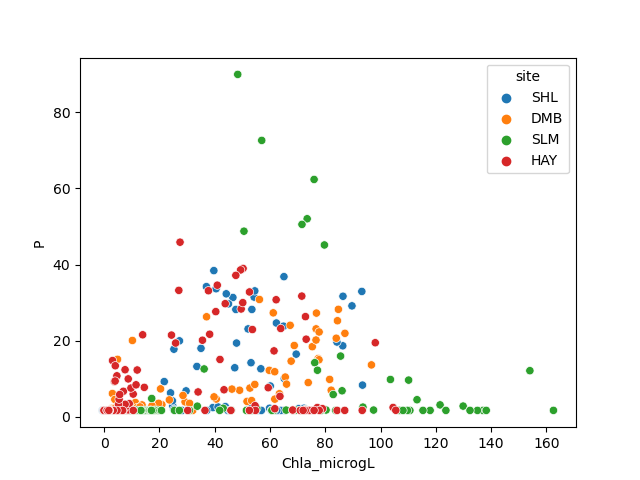

In [32]:
fig,ax=plt.subplots()

sns.scatterplot(data=model.df_merged, x='Chla_microgL', y='P', hue='site')

''

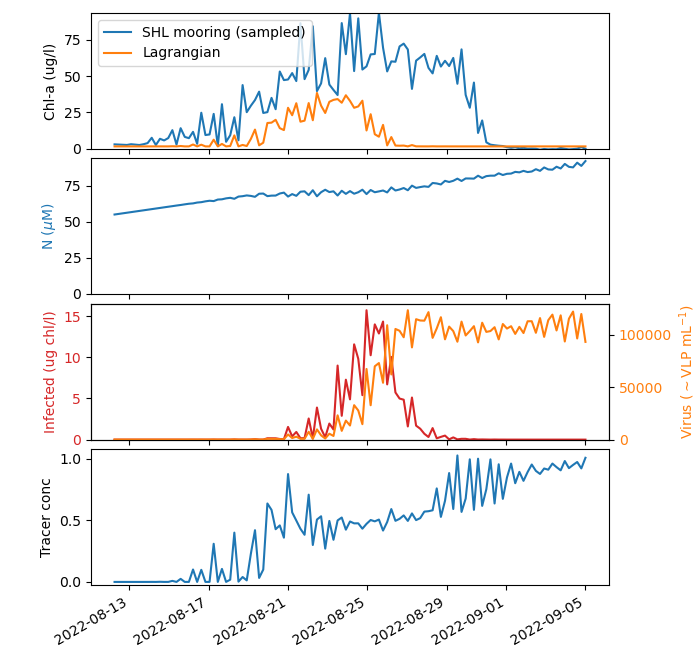

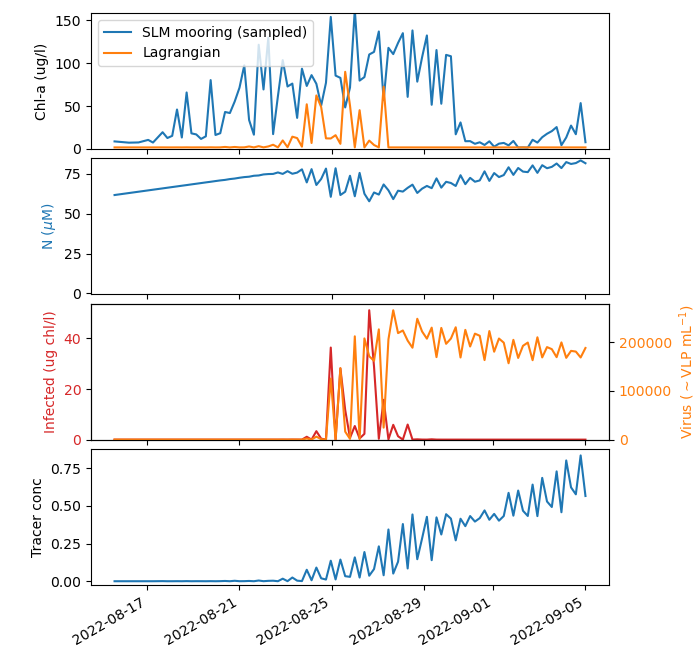

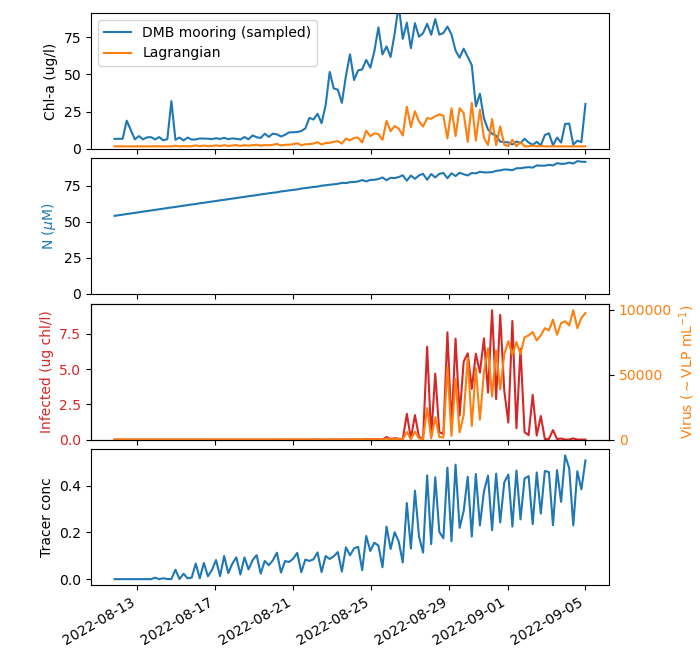

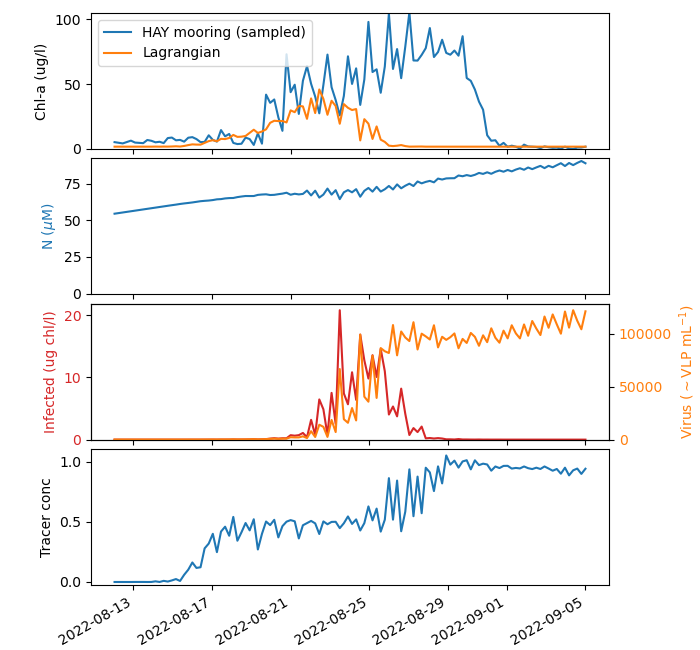

In [34]:
if model.parameter_sets[-1]['k_infect'] > 0.0:
    fig_fn = fig_time_series_with_virus
else:
    fig_fn = fig_time_series 
    
fig_fn(model, mask = model.df_inputs.site.values=='SHL')
fig_fn(model, mask = model.df_inputs.site.values=='SLM')
fig_fn(model, mask = model.df_inputs.site.values=='DMB')
fig_fn(model, mask = model.df_inputs.site.values=='HAY')

;

Optimization over Remote-sensed Chlorophyll
--

In [179]:
# Prepare input across RS scenes:
rs_stride=250
rs_clip=(547000.0, 583300.0, 4145870.0, 4189355.0) # clip out some ponds, ALV, Coyote
df_rs = prepare_spatial_with_all_RS_input(tg, zoom=rs_clip, stride=rs_stride)
print(f"Total records: {len(df_rs)}")

Match RS scene @ 2022-08-04T18:30:00.000000 to tracer output @ 2022-08-04T18:20:00.000000000
Match RS scene @ 2022-08-05T18:30:00.000000 to tracer output @ 2022-08-05T18:20:00.000000000
Match RS scene @ 2022-08-06T18:30:00.000000 to tracer output @ 2022-08-06T18:20:00.000000000
Match RS scene @ 2022-08-07T18:30:00.000000 to tracer output @ 2022-08-07T18:20:00.000000000
Match RS scene @ 2022-08-08T18:30:00.000000 to tracer output @ 2022-08-08T18:20:00.000000000
Match RS scene @ 2022-08-09T18:30:00.000000 to tracer output @ 2022-08-09T18:20:00.000000000
Match RS scene @ 2022-08-10T18:30:00.000000 to tracer output @ 2022-08-10T18:20:00.000000000
Match RS scene @ 2022-08-11T18:30:00.000000 to tracer output @ 2022-08-11T18:20:00.000000000
Match RS scene @ 2022-08-12T18:30:00.000000 to tracer output @ 2022-08-12T18:20:00.000000000
Match RS scene @ 2022-08-13T18:30:00.000000 to tracer output @ 2022-08-13T18:20:00.000000000
Match RS scene @ 2022-08-14T18:30:00.000000 to tracer output @ 2022-08

In [180]:
if 1: # prepare model for zooplankton fit to RS data
    params=dict(
        N0=35, # initial DIN, uM
        c0=5, # P0=c0*[tracer]
        Z0=0.0009, # initial zoop. units?
        I0=0.0,
        V0=0.0,
        kprod=1.36, # maximum instantaneous phyto growth rate [1/d]
        Nsat=1.0, # half-sat DIN, uM
        Isat=6.0, # half-sat for light, in some version(?) of W/m2
        kmortP=0.02, # phyto mortality rate [1/d]
        kmortZ=0.18, # zooplankton mortality rate [1/d]
        background=2.0, # baseline chl, added to result after the fact.
        alpha=0.15, # stoichiometry
        Z_efficiency=0.3, # growth efficiency for zoop,
        Z_max_ration=2.05, # maximum ration for zooplankton [1/d]
        mortP_to_N_efficiency = 0.5,
        N_supplement = 0.1, # uM/day
        thresh=1e-2,
        Ivlev=1.0, # Ivlev constant, 1.0  [ 1/(uM N) ]
        k_infect=0.0, # or 6.75e-8 [mL VLP^-1 day^-1] (adjust based on assumed units for P and V)default=5e-9
        lambda_lysis=1.5, # (float): Lysis rate of infected phytoplankton [day^-1]
        B=500, # viruses per 'host unit'; default=500
        k_virus=0.25, # Viral decay/inactivation rate [day^-1]
    )
    
    #params=dict(c0=3, I0=0, N_supplement=0.25, N0=10, kprod=1.6,Isat=3,
    #            Nsat=2, Z_max_ration=2.1, Z0=0.00003, background=2)
    
    model=NPZIVModel(group=tg,
                     df_inputs=df_rs,
                     params=params, layer='mean',
                     drop_by_ageconc=True)
    
    # Which parameters to tune and their bounds
    params_to_tune=[
                    #('N0',5,40),
                    ('c0',0.5,10),
                    ('Z0',0.000005,0.001),
                    # no I
                    # no V
                    ('kprod',0.5,2.0),
                    ('Isat',1.0,30),
                    ('N_supplement',0.1,3),
                    ('Z_max_ration',0.1,4.0), 
                    ('kmortP',0.01,0.5),
                    ('kmortZ',0.05,0.4),
                    ('Z_efficiency',0.1,0.5),
                    #('background',0.5,15.0),
                    #('Nsat',0.1,5.0)
                   ]

    model.df_inputs.to_csv(f"stan/inputs-{tg.tag}-{tg.tracer_short_name}-rs{rs_stride}-20260813.csv",index=False)

TracerGroup Extract time series


INFO:utils:Extract tidx and cell: 199/1699
INFO:utils:Extract tidx and cell: 400/1699
INFO:utils:Extract tidx and cell: 600/1699
INFO:utils:Extract tidx and cell: 799/1699
INFO:utils:Extract tidx and cell: 1000/1699
INFO:utils:Extract tidx and cell: 1201/1699
INFO:utils:Extract tidx and cell: 1402/1699
INFO:utils:Extract tidx and cell: 1601/1699
INFO:utils:Evaluate samples: 1110


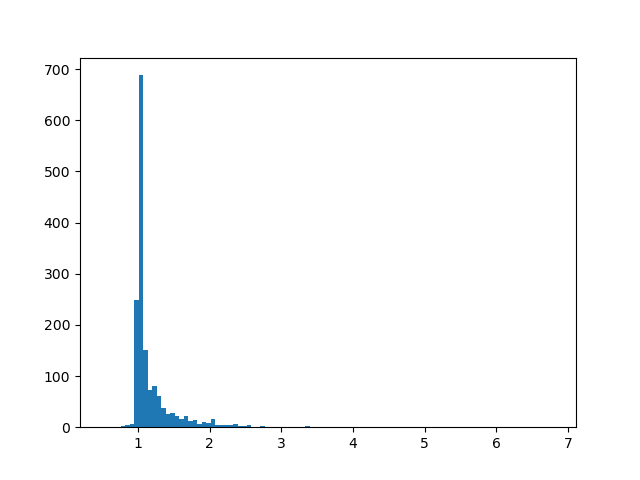

In [177]:
fig,ax = plt.subplots()



In [169]:
#%%prun -s cumulative
#cost_lognormal([model.base_params[p[0]] for p in params_to_tune],model,params_to_tune)

In [128]:
if 1: # Run zoop fitting with log-normal likelihood
    def callback(intermediate_result):
        print(f"Finished an iteration: {intermediate_result.x}")
    minimize(cost_lognormal, 
             x0=[model.base_params[p[0]] for p in params_to_tune],
             # parameters from one round of powell:
             #x0=x0_from_last,
             bounds=[tuple(p[1:]) for p in params_to_tune],
             method='powell',
             callback=callback,
             options=dict(xtol=1e-2),
             args=(model,params_to_tune))

INFO:utils:Evaluate samples: 1128
INFO:utils:Evaluate samples: 1391


5.2824 {'c0': 3.0, 'Z0': 0.0001, 'kprod': 1.8, 'Isat': 5.0, 'N_supplement': 1.0, 'Z_max_ration': 2.0, 'kmortP': 0.05, 'kmortZ': 0.2, 'Z_efficiency': 0.3}


INFO:utils:Evaluate samples: 1100
INFO:utils:Evaluate samples: 1351


5.3190 {'c0': 4.128677106875998, 'Z0': 0.0001, 'kprod': 1.8, 'Isat': 5.0, 'N_supplement': 1.0, 'Z_max_ration': 2.0, 'kmortP': 0.05, 'kmortZ': 0.2, 'Z_efficiency': 0.3}


INFO:utils:Evaluate samples: 1037
INFO:utils:Evaluate samples: 1301
INFO:utils:Evaluate samples: 1485


...

INFO:utils:Evaluate samples: 1215
INFO:utils:Evaluate samples: 1483


1.7771 {'c0': 5.072368774322341, 'Z0': 0.0009057686605290979, 'kprod': 1.3596396446844556, 'Isat': 6.091331164223001, 'N_supplement': 0.10317017971384865, 'Z_max_ration': 2.0478947064404314, 'kmortP': 0.01914608996229669, 'kmortZ': 0.1847144853207732, 'Z_efficiency': 0.29886162004347666}


INFO:utils:Evaluate samples: 1215
INFO:utils:Evaluate samples: 1482


1.7777 {'c0': 5.072368774322341, 'Z0': 0.0009057686605290979, 'kprod': 1.3596396446844556, 'Isat': 6.091331164223001, 'N_supplement': 0.10421700066622679, 'Z_max_ration': 2.0478947064404314, 'kmortP': 0.01914608996229669, 'kmortZ': 0.1847144853207732, 'Z_efficiency': 0.29886162004347666}


KeyboardInterrupt: 

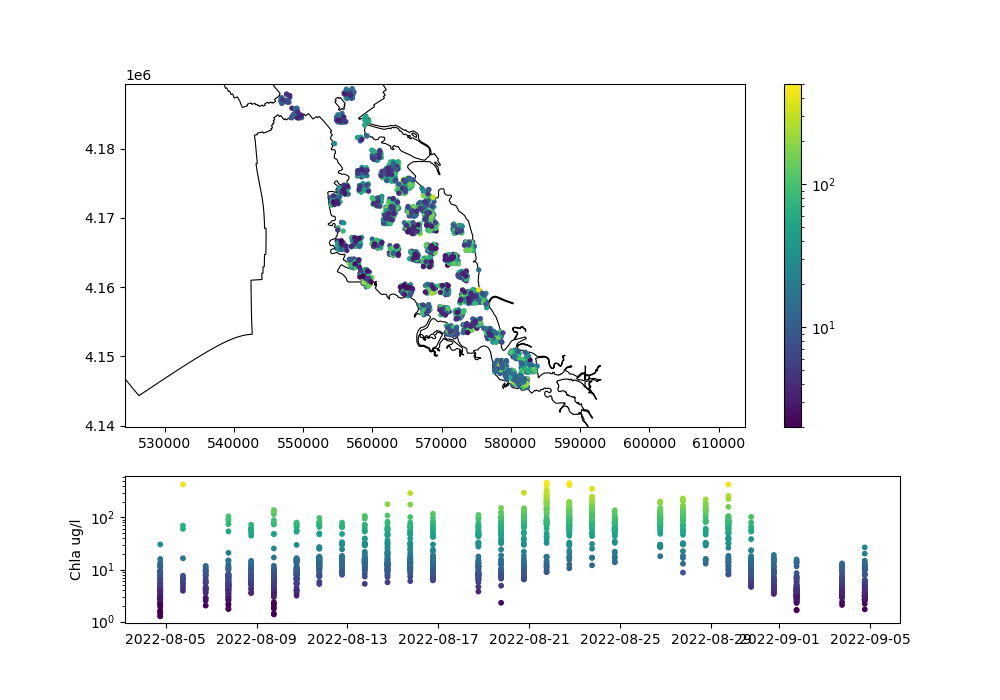

In [170]:
# See what the space/time layout looks like -- at this stride is the data somewhat reasonable?
# Spatial coverage probably sufficient.

fig,(ax_map,ax_time)=plt.subplots(2,1,figsize=(10,7),height_ratios=[0.7,0.3])

tg.grid.plot_boundary_polygon(fc='none',ec='k',lw=0.8,ax=ax_map)

def jitter():
    return 1500*(np.random.random(len(df_rs))-0.5)

norm = colors.LogNorm(vmin=2,vmax=500)
scat = ax_map.scatter(df_rs.x+jitter(), df_rs.y+jitter(), 8, df_rs.Chla_microgL, norm=norm)
plt.colorbar(scat)
ax_map.axis('equal')
ax_map.axis(zoom)

ax_time.scatter(df_rs.time, df_rs.Chla_microgL, 10, df_rs.Chla_microgL, norm=norm)
ax_time.set_ylabel('Chla ug/l')
ax_time.set_yscale('log')


In [82]:
df_rs.head()

,cell,x,y,time,Chla_microgL
150,150,578361.799328,4.151526e+06,2022-08-04 18:20:00,7.817998
300,300,577706.880208,4.155063e+06,2022-08-04 18:20:00,11.315149
600,600,578109.537380,4.148703e+06,2022-08-04 18:20:00,9.166960
1350,1350,578422.302373,4.148418e+06,2022-08-04 18:20:00,9.319358
2250,2250,577000.889713,4.153897e+06,2022-08-04 18:20:00,5.753726


STAN
==

STAN implementation is on CHI-TOWN, developed in a separate py script.

In [47]:
# Assumes a model has been setup and run at least once above
model.df_inputs.to_csv(f"stan/inputs-{tg.tag}-{tg.tracer_short_name}.csv",index=False)

In [ ]:
functions {
  vector my_ode(real t,        // Current time
                vector y,      // Current state variables
                tuple<Nsat, kprod, kLight, kmortP, Z_max_ration, IvLev, k_infect, lambda_lysis, Z_efficiency, kmortZ,
                      alpha, mortP_to_N_efficiency, k_virus, B> params) { 
    // Parameters (can also be an array/tuple if multiple)
    vector[5] dydt;       // Match dimensions to your system
    
    // Example: Simple exponential decay/growth
    //dydt[1] = theta * y[1]; 

    #def npziv_diff(self, t, state, params):
    real N = y[0];
    real P = y[1];
    real Z = y[2];
    real I = y[3];
    real V = y[4];

    // N,P,Z,I,V=np.clip(state,0,None)
        
    real lim_DIN=N/(N+params['Nsat'])

        # No self-shading yet. 
        dgrossP = params['kprod']*params['kLight']*lim_DIN*P
        dmortP = params['kmortP']*P # positive value, but represents loss of P
        # Is this legit? Wikipedia says it is
        dgrazeP = Z*params['Z_max_ration']*(1-np.exp(-params['Ivlev']*P))

        # Virus
        # terms from basic_ode_phyto_graze_virus3.py
        # dPdt = mu_max /Kd_p * P - g * P - k * P * V
        # dIdt = k * P * V - lambda_lysis * I
        # dVdt = B * lambda_lysis * I - k * P * V - d_V * V
        # k (float): Viral infection rate constant (mL VLP^-1 day^-1).
        dinfectP = params['k_infect']*P*V
        
        dnetP = dgrossP - dmortP - dgrazeP - dinfectP

        dlyseI =  params['lambda_lysis'] * I
        
        # From DS equations, phytoplankton, when infected, are removed from P and added to I
        # at which point they lyse at a first order rate, and have no growth.
        dZ = params['Z_efficiency'] * dgrazeP - params['kmortZ']*Z
        # Wikipedia NPZ has 100% recycling efficiency for P and Z, including a (1-Z_efficiency) term
        # for "sloppy grazing"
        dN = (
            - params['alpha']*dgrossP # uptake
            + params['mortP_to_N_efficiency']*params['alpha']*dmortP # recycling
            + params['alpha'] * (1-params['Z_efficiency'])*dgrazeP
            + params['N_supplement'] # uM/day continual source
        )
        
        dI=dinfectP - dlyseI
        dV=params['B']*dlyseI - dinfectP - params['k_virus'] * V
        return np.r_[dN,dnetP,dZ,dI,dV]



    return dydt;
  }
}

data
{
}

transformed data
{
}

parameters
{
}

transformed parameters
{
}

model
{
}

generated quantities
{
}


Animation Output
==

In [ ]:
# Render animation
frame_dir = "frames-bloom_lagrangian_zoop_etal-v002"
force=True # overwrite existing images, but does not proactively delete existing.

if not os.path.exists(frame_dir):
    os.makedirs(frame_dir)
    
with open(os.path.join(frame_dir,'params.txt'),'wt') as fp:
    fp.write("\n".join([
        "Parameters:",
        str(params),
        f"Run dir: {tg.run_dir}",
        f"Tracer suffix: {tg.suffix}",
        f"Swim speed: {tg.swim}",
        f"Initial condition: {tg.initial}",
       ]))
    
times=tg.ds.time.values # all times available in the tracer run
tidxs = np.arange(len(times)) # 
#time_sel = slice(None,None,72) # start idx, stop idx, stride of 3 days
time_sel = slice(None,None) # hourly, start to finish
fig=None
for frame,(tidx,t) in enumerate(zip( tidxs[time_sel], times[time_sel])):
    img_fn=os.path.join(frame_dir,f"frame{frame:04d}.png")
    if os.path.exists(img_fn) and not force:
        print("skipping existing image")
        continue
    df_grid_tidx=df_grid_for_time_idx(tidx)
    tuner=NPZIVModel(group=tg, df_mooring=df_grid_tidx, stride=1, params=params)
    fig = tuner.fig_last_eval_spatial(fig=None)
    fig.savefig(img_fn,dpi=100)

INFO:utils:1729
INFO:utils:1717
INFO:utils:1739
INFO:utils:1900
INFO:utils:2034
INFO:utils:1803
INFO:utils:1736
INFO:utils:1650
INFO:utils:1594
INFO:utils:1563
INFO:utils:1611
INFO:utils:1642
INFO:utils:1663
INFO:utils:1730
INFO:utils:1731
INFO:utils:1745
INFO:utils:1807
INFO:utils:1726
INFO:utils:1659
INFO:utils:1586
INFO:utils:1497
INFO:utils:1451
INFO:utils:1462
INFO:utils:1458
INFO:utils:1476
INFO:utils:1477
INFO:utils:1464
INFO:utils:1484
INFO:utils:1506
INFO:utils:1493
INFO:utils:1496
INFO:utils:1462
INFO:utils:1444
INFO:utils:1451
INFO:utils:1444
INFO:utils:1441
INFO:utils:1447
INFO:utils:1440
INFO:utils:1434
INFO:utils:1450
INFO:utils:1447
INFO:utils:1448
INFO:utils:1439
INFO:utils:1434
INFO:utils:1428
INFO:utils:1400
INFO:utils:1386
INFO:utils:1382
INFO:utils:1390
INFO:utils:1392
INFO:utils:1386
INFO:utils:1377
INFO:utils:1374
INFO:utils:1389
INFO:utils:1399
INFO:utils:1399
INFO:utils:1388
INFO:utils:1365
INFO:utils:1375
INFO:utils:1367
INFO:utils:1365
INFO:utils:1359
INFO:uti

TracerGroup Extract multiple cells, single time step


INFO:utils:1084
INFO:utils:1805


TracerGroup Extract multiple cells, single time step


INFO:utils:1081
INFO:utils:1786


...

TracerGroup Extract multiple cells, single time step


INFO:utils:842
INFO:utils:1392


TracerGroup Extract multiple cells, single time step


INFO:utils:837
INFO:utils:1384


TracerGroup Extract multiple cells, single time step


In [186]:
# Compile frames into movie
movie_out=os.path.join(frame_dir,'output.mp4')
mkanim.mkanim(movie_out,frame_dir+"/frame%04d.png")

ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab

In [191]:
# Display resulting animation
Video(movie_out)

NPZIV Notes
==



In [87]:
# Stoichiometry for DIN vs chl
alpha1 = 6.625 # = 1mol N * 106molC/16 mol N = mol C ; 1mol CO2 fixed * 1mol O2 / 1mol CO2 , 1:1
c_chl = 1/0.03
alpha2 = alpha1*12/c_chl # = 2.385 ug chl / umol N ....106 umol C / 16 umol N * 12 ug C / umol C * 0.03 ug chl / 1 ug
alpha2
1.0/alpha2 # uM DIN / ug/l Chl-a

0.41928721174004197

Diagnostics for tidal phase
==

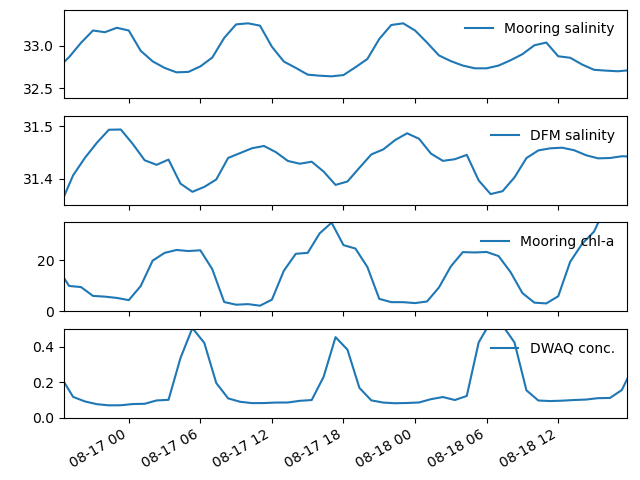

In [215]:
# Is there enough salt to diagnose phase? yes - and phase appears correct.
fig,axs=plt.subplots(4,1,sharex=True)
axs[0].plot( df_mooring.time, df_mooring.S_PSU, label='Mooring salinity')

axs[1].plot( tg.ds.time.values, tg.ds['sa1'].isel(laydim=15,nFlowElem=16145),
           label='DFM salinity')

axs[2].plot( df_mooring.time, df_mooring.Chla_microgL,label='Mooring chl-a')

axs[3].plot( tg.ds.time.values, tg.ds[f'conc{tg.suffix}'].isel(laydim=15,nFlowElem=16145),
           label='DWAQ conc.')

for ax in axs:
    ax.legend(loc='upper right', frameon=0)
    
fig.autofmt_xdate()
axs[0].axis((19220.7738, 19222.7409, 32.38, 33.43))
axs[1].axis(ymin=31.35,ymax=31.52)
axs[2].axis(ymin=0,ymax=35)
axs[3].axis(ymin=0,ymax=0.5)
fig.subplots_adjust(right=0.98,bottom=0.13,top=0.98,left=0.10)


Vertical mixing of P vs N
==

Most of the Lagrangian analysis to date has considered a single layer in isolation.

In reality, the vertical distribution is dynamic, and we're more interested in the
water-column averaged growth, optionally transformed to reflect the surface concentration
for comparison to RS data.

The integration expects initial values for $N$, $P$, $Z$, $I$, and $V$, with $P$ 
based on tracer results. Most of these are unchanged since they already represent
an average concentration with no notion of vertical variability. The one change is
$P$, which should be the vertical average, including the variable layer thicknesses.

Tracer results additionally provide $k_{light}$, based on light tracers. This is 
currently calculated from the local kRadA/kRadB,IsatA,IsatB values.

I think the approach is then to calculate kLight for each layer, and then combine
with a biomass-weighted average. There is some room for misinterpretation here -
it will be biomass weighted average before any growth.  An alternative would
be to evolve each layer as a separate state variable. Sounds slow. We're assuming
that things mix tidally.

Think through some mental experiments:

 - what happens if there is no swimming, all P is evenly distributed in the vertical?
   Physically what happens is that all layer are the same. There could be some short-term
   difference in kLight between the surface and at depth, but in general vertical mixing
   will make the time-average kLight approximately uniform. That makes growth rate uniform,
   and there's really no difference between looking at the surface layer or the vertical mean.
 - what happens if there is extreme swimming, all P is in the top layer, but has access
   to N from the entire water column?
   In this case the biomass-weighted average growth rate will be the growth rate of the
   tracer in the top layer. The growth rate in all of the layer will be higher than in the
   mixed case, and the growth rate in the top layer biased even higher. The mean P concentration
   will be much smaller than the concentration in the surface, and relative to the N initial
   condition it will have more nutrients.
 - other scenarios? There could be some errors in the in-between cases, where exponential
   growth at the surface outpaces that at depth, and the biomass-weighted growth rate
   essentially varies with time.

This is unlikely to come out exact - we're looking at a sum of exponentials with different exponents. But
given that there will be periodic vertical mixing, maybe it's not such a bad approximation.

The key points to check/implement are:

 1. layer='mean' should account for the differing layer thicknesses
 2. kLight calculation should be a biomass-weighted average of the per-layer growth rates.

Turns out step (1) was already there. For step (2), the existing code does a biomass-weighted
average of kRadA and kRadB. It's not quite the same as calculating kLight per layer and then 
biomass-weighted avearge of the per-layer values. But I think it's not that far off. Better
to forge ahead with the optimization

Come back to taking a closer look at the vertical integration, work through the calculations
by hand.

```
            constant_params['kLight']=bloom_common.calc_kLight(Isat=constant_params['Isat'],
                                                               kRadA=row.kRadA,IsatA=row.IsatA,
                                                               kRadB=row.kRadB,IsatB=row.IsatB,
                                                               conc=row.conc,age_d=row.age_d)
```